## Comparing XGBoost vs GNN vs GCN on IEEE-CIS Fraud Detection Datset- Which produces the best results and why? 

### Part 1: EDA and Slight Feature Engineering

In [1]:
import kagglehub

#kagglehub.login()

# Download latest version
path = kagglehub.competition_download('ieee-fraud-detection')

print("Path to competition files:", path)

Path to competition files: C:\Users\vvyah\.cache\kagglehub\competitions\ieee-fraud-detection


In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv(path + '/train_transaction.csv')
df.head(5)

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
target = df['isFraud']
splitter = df['TransactionDT']

split_time = splitter.quantile(0.8)
train_mask = splitter <= split_time
test_mask = splitter > split_time
df_train = df[train_mask]
df_test = df[test_mask]
y_train = target[train_mask]
y_test = target[test_mask]

print(f"shape : {df_train.shape}, {df_test.shape}")
print(f"fraud ratio : {y_train.mean():.4f}, {y_test.mean():.4f}")

shape : (472432, 394), (118108, 394)
fraud ratio : 0.0351, 0.0344


In [5]:
for num in range(1, 339,  10):
    col_name = "V" + str(num)
    print(df[col_name].value_counts(dropna=False))


V1
1.0    311236
NaN    279287
0.0        17
Name: count, dtype: int64
V11
NaN    279287
0.0    169633
1.0    135148
2.0      5672
3.0       608
4.0       190
5.0         2
Name: count, dtype: int64
V21
0.0    448220
NaN     76073
1.0     65837
2.0       354
3.0        53
5.0         2
4.0         1
Name: count, dtype: int64
V31
0.0    443045
NaN     76073
1.0     70729
2.0       477
3.0       167
4.0        33
7.0        10
5.0         5
6.0         1
Name: count, dtype: int64
V41
1.0    421263
NaN    168969
0.0       308
Name: count, dtype: int64
V51
0.0    353522
NaN    168969
1.0     64775
2.0      2780
3.0       416
4.0        66
5.0         8
6.0         4
Name: count, dtype: int64
V61
1.0    404182
0.0     98827
NaN     77096
2.0      9620
3.0       702
5.0        60
4.0        49
6.0         4
Name: count, dtype: int64
V71
0.0    443821
NaN     77096
1.0     67435
2.0      1837
3.0       311
4.0        34
5.0         4
6.0         2
Name: count, dtype: int64
V81
0.0     434653


In [6]:
v_cols = [c for c in df.columns if c.startswith("V") and c[1:].isdigit()]
print(f"Found {len(v_cols)} V-columns")

Found 339 V-columns


In [7]:
nan_counts= df_train[v_cols].isna().sum()
groups = {}
for col, n_missing in nan_counts.items():
    groups.setdefault(n_missing, []).append(col)

In [8]:
print(f"{len(groups)} distinct missingness counts found")
for n_missing, cols in sorted(groups.items(), key=lambda x: -len(x[1])):
    print(f"  NaN count = {n_missing} | {len(cols)} columns | e.g. {cols[:3]}")

14 distinct missingness counts found
  NaN count = 362497 | 46 columns | e.g. ['V217', 'V218', 'V219']
  NaN count = 97 | 43 columns | e.g. ['V95', 'V96', 'V97']
  NaN count = 12 | 32 columns | e.g. ['V279', 'V280', 'V284']
  NaN count = 355933 | 31 columns | e.g. ['V167', 'V168', 'V172']
  NaN count = 402728 | 29 columns | e.g. ['V138', 'V139', 'V140']
  NaN count = 66427 | 23 columns | e.g. ['V12', 'V13', 'V14']
  NaN count = 66890 | 22 columns | e.g. ['V53', 'V54', 'V55']
  NaN count = 77793 | 20 columns | e.g. ['V75', 'V76', 'V77']
  NaN count = 355767 | 19 columns | e.g. ['V169', 'V170', 'V171']
  NaN count = 139809 | 18 columns | e.g. ['V35', 'V36', 'V37']
  NaN count = 402411 | 18 columns | e.g. ['V322', 'V323', 'V324']
  NaN count = 354412 | 16 columns | e.g. ['V220', 'V221', 'V222']
  NaN count = 245973 | 11 columns | e.g. ['V1', 'V2', 'V3']
  NaN count = 936 | 11 columns | e.g. ['V281', 'V282', 'V283']


In [9]:
refined_groups = {}
group_id = 0

for n_missing, cols in groups.items():
    if len(cols) == 1:
        refined_groups[f"group_{group_id}"] = cols
        group_id += 1
        continue

    masks = df_train[cols].isna()
    seen = {}  
    for col in cols:
        mask_key = tuple(masks[col].values) 
        seen.setdefault(mask_key, []).append(col)

    for mask_key, matching_cols in seen.items():
        refined_groups[f"group_{group_id}"] = matching_cols
        group_id += 1

In [10]:
print(f"\n--- After exact mask verification ---")
print(f"{len(refined_groups)} true groups (was {len(groups)} count-based groups)")
for gid, cols in sorted(refined_groups.items(), key=lambda x: -len(x[1])):
    if len(cols) > 1:
        print(f"  {gid}: {len(cols)} columns | e.g. {cols[:3]}")


--- After exact mask verification ---
14 true groups (was 14 count-based groups)
  group_9: 46 columns | e.g. ['V217', 'V218', 'V219']
  group_5: 43 columns | e.g. ['V95', 'V96', 'V97']
  group_11: 32 columns | e.g. ['V279', 'V280', 'V284']
  group_7: 31 columns | e.g. ['V167', 'V168', 'V172']
  group_6: 29 columns | e.g. ['V138', 'V139', 'V140']
  group_1: 23 columns | e.g. ['V12', 'V13', 'V14']
  group_3: 22 columns | e.g. ['V53', 'V54', 'V55']
  group_4: 20 columns | e.g. ['V75', 'V76', 'V77']
  group_8: 19 columns | e.g. ['V169', 'V170', 'V171']
  group_2: 18 columns | e.g. ['V35', 'V36', 'V37']
  group_13: 18 columns | e.g. ['V322', 'V323', 'V324']
  group_10: 16 columns | e.g. ['V220', 'V221', 'V222']
  group_0: 11 columns | e.g. ['V1', 'V2', 'V3']
  group_12: 11 columns | e.g. ['V281', 'V282', 'V283']


In [11]:
def compute_corr_matrix(df, cols):
    full = df[cols].dropna()
    matrix = full.corr(method = "spearman")
    return matrix

def correlated_clusters(matrix):
    cols = matrix.columns.tolist()
    parent = {c: c for c in cols}  
 
    def find(x):
        while parent[x] != x:
            x = parent[x]
        return x
 
    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[ra] = rb

    mask = np.triu(np.ones(matrix.shape), k=1).astype(bool)
    pairs = matrix.where(mask).stack().reset_index()
    pairs.columns = ['Feature_1', 'Feature_2', 'Correlation']
    highly_correlated_pairs = pairs[pairs['Correlation'].abs() > 0.9]
    for _, row in highly_correlated_pairs.iterrows():
        union(row["Feature_1"], row["Feature_2"])

    clusters = {}
    for c in cols:
        root = find(c)
        clusters.setdefault(root, []).append(c)
 
    return list(clusters.values()) 

def drop_correlated(df, cols):
    matrix = compute_corr_matrix(df, cols)
    clusters = correlated_clusters(matrix)
    kept = []
    dropped = []
    for cluster in clusters:
        if len(cluster) == 1:
            kept.append(cluster[0])
        else:
            best = df[cluster].var().idxmax()
            kept.append(best)
            dropped.extend([c for c in cluster if c != best])

    print(f"  group had {len(cols)} cols -> keeping {len(kept)} "
          f"(dropped {len(dropped)}: {dropped[:5]}{'...' if len(dropped) > 5 else ''})")

    return kept, dropped

In [12]:
all_kept_cols = []
for group, cols in refined_groups.items():
    print(f"{group}:")
    kept, dropped = drop_correlated(df_train, cols)
    all_kept_cols.extend(kept)

print(f"\nTotal: {len(all_kept_cols)} columns kept out of 339")

group_0:
  group had 11 cols -> keeping 9 (dropped 2: ['V4', 'V10'])
group_1:
  group had 23 cols -> keeping 10 (dropped 13: ['V12', 'V15', 'V16', 'V17', 'V21']...)
group_2:
  group had 18 cols -> keeping 10 (dropped 8: ['V35', 'V39', 'V42', 'V43', 'V50']...)
group_3:
  group had 22 cols -> keeping 10 (dropped 12: ['V53', 'V57', 'V58', 'V59', 'V63']...)
group_4:
  group had 20 cols -> keeping 10 (dropped 10: ['V75', 'V79', 'V80', 'V84', 'V85']...)
group_5:
  group had 43 cols -> keeping 30 (dropped 13: ['V95', 'V96', 'V97', 'V98', 'V99']...)
group_6:
  group had 29 cols -> keeping 8 (dropped 21: ['V139', 'V148', 'V149', 'V153', 'V154']...)
group_7:
  group had 31 cols -> keeping 13 (dropped 18: ['V167', 'V168', 'V202', 'V204', 'V172']...)
group_8:
  group had 19 cols -> keeping 8 (dropped 11: ['V170', 'V174', 'V175', 'V208', 'V210']...)
group_9:
  group had 46 cols -> keeping 23 (dropped 23: ['V217', 'V218', 'V219', 'V263', 'V265']...)
group_10:
  group had 16 cols -> keeping 6 (droppe

In [13]:
group_5_cols = refined_groups["group_5"]
total_rows = len(df_train)
surviving_rows = df_train[group_5_cols].dropna().shape[0]
pct_surviving = surviving_rows / total_rows * 100
 
print("--- group_5 row survival check ---")
print(f"Total rows in df:        {total_rows}")
print(f"Rows surviving dropna(): {surviving_rows} ({pct_surviving:.1f}%)")
 
group5_corr = df_train[group_5_cols].dropna().corr(method="spearman")
print("\nCorrelation matrix (group_5):")
print(group5_corr.round(2))

--- group_5 row survival check ---
Total rows in df:        472432
Rows surviving dropna(): 472335 (100.0%)

Correlation matrix (group_5):
       V95   V96   V97   V98   V99  V100  V101  V102  V103  V104  ...  V128  \
V95   1.00  0.52  0.74  0.60  0.25  0.40  0.64  0.53  0.58  0.54  ...  0.74   
V96   0.52  1.00  0.74  0.33  0.89  0.62  0.35  0.48  0.41  0.26  ...  0.73   
V97   0.74  0.74  1.00  0.45  0.54  0.80  0.49  0.54  0.56  0.39  ...  0.99   
V98   0.60  0.33  0.45  1.00  0.36  0.56  0.17  0.18  0.17  0.04  ...  0.44   
V99   0.25  0.89  0.54  0.36  1.00  0.68  0.11  0.25  0.17  0.01  ...  0.53   
V100  0.40  0.62  0.80  0.56  0.68  1.00  0.19  0.29  0.25  0.02  ...  0.78   
V101  0.64  0.35  0.49  0.17  0.11  0.19  1.00  0.77  0.88  0.04  ...  0.48   
V102  0.53  0.48  0.54  0.18  0.25  0.29  0.77  1.00  0.87  0.04  ...  0.53   
V103  0.58  0.41  0.56  0.17  0.17  0.25  0.88  0.87  1.00  0.04  ...  0.54   
V104  0.54  0.26  0.39  0.04  0.01  0.02  0.04  0.04  0.04  1.00  ...  

In [14]:
group6_cols = refined_groups["group_6"]
 
group6_sub = df_train[group6_cols].dropna()
group6_corr = group6_sub.corr(method="spearman")
 
print("\n--- group_6 correlation matrix ---")
print(group6_corr.round(2))


--- group_6 correlation matrix ---
      V138  V139  V140  V141  V142  V143  V144  V145  V146  V147  ...  V157  \
V138  1.00  0.21  0.21  0.67  0.68  0.01 -0.00  0.00  0.09  0.10  ...  0.13   
V139  0.21  1.00  0.99  0.19  0.19 -0.28 -0.29 -0.31  0.50  0.50  ...  0.91   
V140  0.21  0.99  1.00  0.24  0.24 -0.27 -0.28 -0.30  0.50  0.51  ...  0.90   
V141  0.67  0.19  0.24  1.00  0.99 -0.01 -0.03 -0.02  0.06  0.09  ...  0.14   
V142  0.68  0.19  0.24  0.99  1.00 -0.02 -0.04 -0.02  0.06  0.09  ...  0.14   
V143  0.01 -0.28 -0.27 -0.01 -0.02  1.00  0.69  0.70 -0.02 -0.01  ... -0.41   
V144 -0.00 -0.29 -0.28 -0.03 -0.04  0.69  1.00  0.97  0.41  0.40  ... -0.43   
V145  0.00 -0.31 -0.30 -0.02 -0.02  0.70  0.97  1.00  0.41  0.41  ... -0.45   
V146  0.09  0.50  0.50  0.06  0.06 -0.02  0.41  0.41  1.00  0.99  ...  0.32   
V147  0.10  0.50  0.51  0.09  0.09 -0.01  0.40  0.41  0.99  1.00  ...  0.32   
V148  0.09  0.87  0.87  0.12  0.12 -0.50 -0.51 -0.53  0.23  0.23  ...  0.95   
V149  0.09  0.87

In [15]:
print("\n--- group_6 near-constant check ---")
for col in group6_cols:
    n_unique = group6_sub[col].nunique()
    top_value_share = group6_sub[col].value_counts(normalize=True).iloc[0]
    print(f"{col}: {n_unique} unique values, "
          f"top value = {top_value_share:.1%} of rows")

#everything's good


--- group_6 near-constant check ---
V138: 23 unique values, top value = 98.3% of rows
V139: 34 unique values, top value = 59.1% of rows
V140: 34 unique values, top value = 58.2% of rows
V141: 6 unique values, top value = 96.7% of rows
V142: 10 unique values, top value = 96.7% of rows
V143: 55 unique values, top value = 78.0% of rows
V144: 63 unique values, top value = 77.0% of rows
V145: 255 unique values, top value = 75.7% of rows
V146: 18 unique values, top value = 91.6% of rows
V147: 18 unique values, top value = 91.4% of rows
V148: 16 unique values, top value = 72.6% of rows
V149: 16 unique values, top value = 72.2% of rows
V150: 1985 unique values, top value = 81.2% of rows
V151: 56 unique values, top value = 84.2% of rows
V152: 29 unique values, top value = 83.4% of rows
V153: 8 unique values, top value = 73.1% of rows
V154: 9 unique values, top value = 73.0% of rows
V155: 15 unique values, top value = 72.5% of rows
V156: 17 unique values, top value = 72.1% of rows
V157: 16 uniq

In [16]:
print(df_train.columns.tolist())

['TransactionID', 'isFraud', 'TransactionDT', 'TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'dist1', 'dist2', 'P_emaildomain', 'R_emaildomain', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'V29', 'V30', 'V31', 'V32', 'V33', 'V34', 'V35', 'V36', 'V37', 'V38', 'V39', 'V40', 'V41', 'V42', 'V43', 'V44', 'V45', 'V46', 'V47', 'V48', 'V49', 'V50', 'V51', 'V52', 'V53', 'V54', 'V55', 'V56', 'V57', 'V58', 'V59', 'V60', 'V61', 'V62', 'V63', 'V64', 'V65', 'V66', 'V67', 'V68', 'V69', 'V70', 'V71', 'V72', 'V73', 'V74', 'V75', 'V76', 'V77', 'V78', 'V79', 'V80', 'V81', 'V

In [17]:
d_cols = [c for c in df_train.columns if c.startswith("D") and c[1:].isdigit()]
print(len(d_cols))

nan_counts= df_train[d_cols].isna().sum()
groupsD = {}
for col, n_missing in nan_counts.items():
    groupsD.setdefault(n_missing, []).append(col)

print(f"{len(groupsD)} distinct missingness counts found")
for n_missing, cols in sorted(groupsD.items(), key=lambda x: -len(x[1])):
    print(f"  NaN count = {n_missing} | {len(cols)} columns | e.g. {cols[:3]}")

15
14 distinct missingness counts found
  NaN count = 410822 | 2 columns | e.g. ['D8', 'D9']
  NaN count = 936 | 1 columns | e.g. ['D1']
  NaN count = 231263 | 1 columns | e.g. ['D2']
  NaN count = 217652 | 1 columns | e.g. ['D3']
  NaN count = 139774 | 1 columns | e.g. ['D4']
  NaN count = 253845 | 1 columns | e.g. ['D5']
  NaN count = 413949 | 1 columns | e.g. ['D6']
  NaN count = 442488 | 1 columns | e.g. ['D7']
  NaN count = 66391 | 1 columns | e.g. ['D10']
  NaN count = 245973 | 1 columns | e.g. ['D11']
  NaN count = 419729 | 1 columns | e.g. ['D12']
  NaN count = 423459 | 1 columns | e.g. ['D13']
  NaN count = 422596 | 1 columns | e.g. ['D14']
  NaN count = 77765 | 1 columns | e.g. ['D15']


In [18]:
#So no block duplication like the V-columns; could still be highly correlated though
def compute_corr_matrix_forD(df, cols):
    matrix = df[cols].corr(method = "spearman")
    return matrix


corrs_for_D = correlated_clusters(compute_corr_matrix_forD(df_train, d_cols))

print(corrs_for_D)

[['D1', 'D2'], ['D3'], ['D4', 'D6', 'D12'], ['D5', 'D7'], ['D8'], ['D9'], ['D10'], ['D11'], ['D13'], ['D14'], ['D15']]


In [19]:
def drop_correlated_forD(corrs, total_cols):
    clusters = corrs
    kept = []
    dropped = []
    for cluster in clusters:
        if len(cluster) == 1:
            kept.append(cluster[0])
        else:
            best = df_train[cluster].var().idxmax()
            kept.append(best)
            dropped.extend([c for c in cluster if c != best])

    print(f"  group had {total_cols} cols -> keeping {len(kept)} "
          f"(dropped {len(dropped)}: {dropped[:5]}{'...' if len(dropped) > 5 else ''})")

    return kept

kept_cols_forD = drop_correlated_forD(corrs_for_D, len(d_cols))

  group had 15 cols -> keeping 11 (dropped 4: ['D1', 'D6', 'D12', 'D5'])


In [20]:
#Now for the C-columns which likely have a lot of duplication and correlation

c_cols = [c for c in df_train.columns if c.startswith("C") and c[1:].isdigit()]

corrs_for_C = correlated_clusters(compute_corr_matrix_forD(df_train, c_cols))
print(corrs_for_C)

[['C1'], ['C2'], ['C3'], ['C4', 'C8', 'C10'], ['C5'], ['C6'], ['C7'], ['C9'], ['C11'], ['C12'], ['C13'], ['C14']]


In [21]:
print(df_train[c_cols].corr(method="spearman").round(2))

       C1    C2    C3    C4    C5    C6    C7    C8    C9   C10   C11   C12  \
C1   1.00  0.74 -0.04 -0.17  0.47  0.65 -0.06 -0.18  0.57 -0.17  0.74 -0.02   
C2   0.74  1.00 -0.04 -0.07  0.41  0.65  0.09 -0.08  0.49 -0.07  0.76  0.12   
C3  -0.04 -0.04  1.00  0.09 -0.05 -0.11 -0.02  0.10 -0.08  0.10 -0.03 -0.03   
C4  -0.17 -0.07  0.09  1.00 -0.42 -0.15  0.65  0.91 -0.69  0.88 -0.08  0.51   
C5   0.47  0.41 -0.05 -0.42  1.00  0.41 -0.27 -0.42  0.56 -0.41  0.47 -0.27   
C6   0.65  0.65 -0.11 -0.15  0.41  1.00 -0.02 -0.17  0.52 -0.17  0.68  0.01   
C7  -0.06  0.09 -0.02  0.65 -0.27 -0.02  1.00  0.57 -0.44  0.54  0.02  0.85   
C8  -0.18 -0.08  0.10  0.91 -0.42 -0.17  0.57  1.00 -0.70  0.97 -0.10  0.45   
C9   0.57  0.49 -0.08 -0.69  0.56  0.52 -0.44 -0.70  1.00 -0.68  0.53 -0.31   
C10 -0.17 -0.07  0.10  0.88 -0.41 -0.17  0.54  0.97 -0.68  1.00 -0.09  0.42   
C11  0.74  0.76 -0.03 -0.08  0.47  0.68  0.02 -0.10  0.53 -0.09  1.00  0.05   
C12 -0.02  0.12 -0.03  0.51 -0.27  0.01  0.85  0.45 

In [22]:
kept_cols_forC = drop_correlated_forD(corrs_for_C, len(c_cols))

  group had 14 cols -> keeping 12 (dropped 2: ['C4', 'C8'])


In [23]:
for num in range(1, 9):
    name = "M" + str(num)
    print(df_train[name].isna().sum())

238295
238295
238295
227191
283514
141415
299980
299974


In [24]:
m_cols = [c for c in df_train.columns if c.startswith("M") and c[1:].isdigit()]

for col in m_cols:
    print(f"{col}: {df_train[col].value_counts(dropna=False)}")

M1: M1
NaN    238295
T      234116
F          21
Name: count, dtype: int64
M2: M2
NaN    238295
T      210007
F       24130
Name: count, dtype: int64
M3: M3
NaN    238295
T      184780
F       49357
Name: count, dtype: int64
M4: M4
NaN    227191
M0     155071
M2      48778
M1      41392
Name: count, dtype: int64
M5: M5
NaN    283514
F      104333
T       84585
Name: count, dtype: int64
M6: M6
F      179001
T      152016
NaN    141415
Name: count, dtype: int64
M7: M7
NaN    299980
F      149126
T       23326
Name: count, dtype: int64
M8: M8
NaN    299974
F      109063
T       63395
Name: count, dtype: int64
M9: M9
NaN    299974
T      145732
F       26726
Name: count, dtype: int64


In [25]:
import sklearn
from sklearn.preprocessing import OneHotEncoder

categorical_cols = m_cols + ["card4", "card6"]

encoded_cat_train, encoded_cat_test = [], []

for col in categorical_cols:
    ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
    ohe.fit(df_train[[col]])
    tr = ohe.transform(df_train[[col]])
    te = ohe.transform(df_test[[col]])
    names = ohe.get_feature_names_out([col])
    col_names = ohe.get_feature_names_out([col])
    encoded_cat_train.append(pd.DataFrame(tr, columns=col_names, index=df_train.index))
    encoded_cat_test.append(pd.DataFrame(te, columns=col_names, index=df_test.index))

encoded_cat_train_df = pd.concat(encoded_cat_train, axis=1)
encoded_cat_test_df = pd.concat(encoded_cat_test, axis=1)

print(encoded_cat_train_df.shape[1])


38


In [26]:
frequency_encoding_cols = ["card1", "card2", "card3", "card5"]
encoded_frequency_train_df = pd.DataFrame(index = df_train.index)
encoded_frequency_test_df = pd.DataFrame(index = df_test.index)

for col in frequency_encoding_cols:
    freq = df_train[col].value_counts()
    encoded_frequency_train_df[col + "_freq"] = df_train[col].map(freq)
    encoded_frequency_test_df[col + "_freq"] = df_test[col].map(freq)

print(encoded_frequency_train_df.shape[1])


4


In [27]:
the_Vs = df_train[all_kept_cols]
the_Ds = df_train[kept_cols_forD]
the_Cs = df_train[kept_cols_forC]

In [28]:
#['TransactionID', 'TransactionDT', 'TransactionAmt', 'ProductCD', 'addr1', 'addr2', 'dist1', 'dist2', 'P_emaildomain', 'R_emaildomain']

for col in ["addr1", "addr2", "dist1", "dist2"]:
    print(f"{col}: {df_train[col].isna().sum()}")


addr1: 53761
addr2: 53761
dist1: 287157
dist2: 440332


In [29]:
for col in ["P_emaildomain", "R_emaildomain", "ProductCD", "addr2"]:
    print(f"{col}: {df_train[col].value_counts(dropna=False)}")
    print(f"{col}: {df_train[col].nunique(dropna=False)}")

P_emaildomain: P_emaildomain
gmail.com           182692
yahoo.com            80854
NaN                  73586
hotmail.com          37158
anonymous.com        29961
aol.com              22618
comcast.net           6496
icloud.com            5031
outlook.com           4080
msn.com               3340
att.net               3133
live.com              2475
sbcglobal.net         2395
verizon.net           2252
ymail.com             1914
bellsouth.net         1580
yahoo.com.mx          1285
me.com                1269
cox.net               1121
optonline.net          835
charter.net            688
live.com.mx            624
rocketmail.com         520
mail.com               452
gmail                  411
earthlink.net          408
outlook.es             377
mac.com                360
juno.com               271
aim.com                268
roadrunner.com         249
hotmail.es             239
hotmail.fr             226
frontier.com           221
windstream.net         219
embarqmail.com         210

In [30]:
df_train["TransactionAmt"].describe() #-> high skew, will use log1p

count    472432.000000
mean        134.401388
std         237.557972
min           0.251000
25%          42.950000
50%          68.950000
75%         125.000000
max       31937.391000
Name: TransactionAmt, dtype: float64

In [31]:
df_train["addr1"].nunique() #-> frequency encode (high cardinality)

328

In [32]:
print(df_train["P_emaildomain"].isna().sum()) 
print(df_train["R_emaildomain"].isna().sum()) #-> frequency encoding still

73586
358812


In [33]:
corr_dist = compute_corr_matrix_forD(df_train, ["dist1", "dist2"])
print(corr_dist)

       dist1  dist2
dist1    1.0    NaN
dist2    NaN    1.0


In [34]:
amt_df_train = pd.DataFrame(index = df_train.index)
amt_df_train["TransactionAmt"] = df_train["TransactionAmt"]
amt_df_train["TransactionAmt_log1p"] = np.log1p(df_train["TransactionAmt"])

amt_df_test = pd.DataFrame(index = df_test.index)
amt_df_test["TransactionAmt"] = df_test["TransactionAmt"]
amt_df_test["TransactionAmt_log1p"] = np.log1p(df_test["TransactionAmt"])

In [35]:
ohe_productCD = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
ohe_productCD.fit(df_train[["ProductCD"]])
tr = ohe_productCD.transform(df_train[["ProductCD"]])
te = ohe_productCD.transform(df_test[["ProductCD"]])
productCD_encoded_train = pd.DataFrame(tr, columns = ohe_productCD.get_feature_names_out(["ProductCD"]),index = df_train.index)
productCD_encoded_test = pd.DataFrame(te, columns = ohe_productCD.get_feature_names_out(["ProductCD"]), index = df_test.index)

In [36]:
freq_encode_cols2 = ["addr1", "addr2", "P_emaildomain", "R_emaildomain"]
encoded_frequency_train_df2= pd.DataFrame(index = df_train.index)
encoded_frequency_test_df2= pd.DataFrame(index = df_test.index)
for col in freq_encode_cols2:
    freq_map = df_train[col].value_counts()
    encoded_frequency_train_df2[f"{col}_freq"] = df_train[col].map(freq_map)
    encoded_frequency_test_df2[f"{col}_freq"] = df_test[col].map(freq_map)
    print(f"{col}: {encoded_frequency_train_df2[f'{col}_freq'].isna().sum()} NaNs preserved")

addr1: 53761 NaNs preserved
addr2: 53761 NaNs preserved
P_emaildomain: 73586 NaNs preserved
R_emaildomain: 358812 NaNs preserved


In [37]:
dist_df_train = df_train[["dist1", "dist2"]].copy()
dist_df_test = df_test[["dist1", "dist2"]].copy()

X_train = pd.concat([
    df_train[all_kept_cols], df_train[kept_cols_forD], df_train[kept_cols_forC],
    encoded_cat_train_df, encoded_frequency_train_df, amt_df_train,
    productCD_encoded_train, encoded_frequency_train_df2, dist_df_train,
], axis=1)

X_test = pd.concat([
    df_test[all_kept_cols], df_test[kept_cols_forD], df_test[kept_cols_forC],
    encoded_cat_test_df, encoded_frequency_test_df, amt_df_test,
    productCD_encoded_test, encoded_frequency_test_df2, dist_df_test,
], axis=1)

### Part 2: Setting up the XGBoost model, training, and then evaluating it as a baseline

In [38]:
import xgboost 
from xgboost import XGBClassifier

In [39]:
weight = sum(y_train == 0) / sum(y_train == 1)
model = XGBClassifier(n_estimators = 300, enable_categorical = False, scale_pos_weight = weight)
model.fit(X_train, y_train)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XG

In [40]:
y_pred = model.predict(X_test)

from sklearn.metrics import classification_report, auc, precision_recall_curve

print(classification_report(y_test, y_pred))

y_probs = model.predict_proba(X_test)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_test, y_probs)
auprc_auc = auc(recall, precision)
print(auprc_auc)

              precision    recall  f1-score   support

           0       0.99      0.96      0.97    114044
           1       0.33      0.61      0.43      4064

    accuracy                           0.94    118108
   macro avg       0.66      0.78      0.70    118108
weighted avg       0.96      0.94      0.95    118108

0.5171406341629812


In [41]:
naive_baseline = y_test.mean()

print(f"Naive baseline AUPRC (~= fraud rate): {naive_baseline:.4f}")
print(f"Your model's lift over naive: {auprc_auc / naive_baseline:.2f}x")

Naive baseline AUPRC (~= fraud rate): 0.0344
Your model's lift over naive: 15.03x


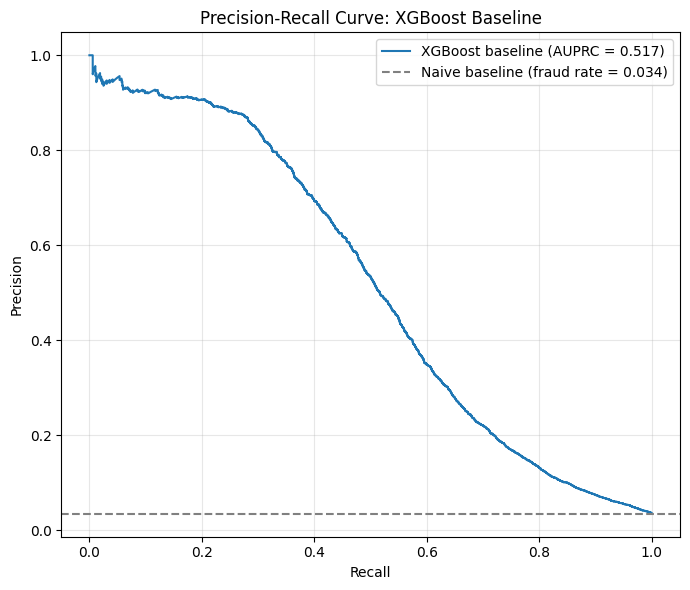

Saved to pr_curve_baseline.png


In [42]:
import matplotlib.pyplot as plt
 
plt.figure(figsize=(7, 6))
plt.plot(recall, precision, label=f"XGBoost baseline (AUPRC = {auprc_auc:.3f})")
 

plt.axhline(y=naive_baseline, color="gray", linestyle="--",
            label=f"Naive baseline (fraud rate = {naive_baseline:.3f})")
 
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve: XGBoost Baseline")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("pr_curve_baseline.png", dpi=150)
plt.show()
 
print("Saved to pr_curve_baseline.png")

#### Checking the importances of features to understand what the model relied on

In [43]:
importances = pd.Series(model.feature_importances_, index = X_train.columns)
importances = importances.sort_values(ascending=False)

print(importances.head(30))

V258            0.232395
V317            0.045485
ProductCD_W     0.043115
V91             0.039739
card6_debit     0.034841
V70             0.032020
V201            0.029815
V187            0.024811
C14             0.018174
V162            0.016859
C10             0.013241
V308            0.009769
C11             0.007949
C5              0.007874
ProductCD_H     0.007300
card3_freq      0.007227
V296            0.006868
V336            0.006712
V49             0.005667
V309            0.005488
C1              0.005327
ProductCD_R     0.005321
D2              0.005222
M6_T            0.005211
M6_F            0.005064
M5_T            0.004942
card6_credit    0.004895
V338            0.004820
V165            0.004744
C3              0.004725
dtype: float32


In [ ]:
#V258 looks a little suspicious- it has 23% importance
df_train.groupby("isFraud")["V258"].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,101761.0,1.167697,1.626001,0.0,1.0,1.0,1.0,66.0
1,8174.0,3.466357,4.726876,0.0,1.0,2.0,4.0,48.0


In [45]:
importances = importances.sort_values(ascending=True)

print(importances.head(30))

card6_debit or credit    0.000000
M9_nan                   0.000000
M1_nan                   0.000000
V122                     0.000000
V88                      0.000000
V89                      0.000000
V241                     0.000000
V240                     0.000000
V305                     0.000000
V112                     0.000000
V28                      0.000000
V41                      0.000000
M3_nan                   0.000000
M2_nan                   0.000000
V120                     0.000000
M1_F                     0.000000
V113                     0.000000
ProductCD_C              0.000000
V107                     0.000000
V119                     0.000000
TransactionAmt_log1p     0.000000
card6_charge card        0.000000
V114                     0.000026
V1                       0.000109
V68                      0.000126
V186                     0.000165
V226                     0.000263
V246                     0.000297
V117                     0.000314
V196          

In [46]:
booster = model.get_booster()

weight_importance = booster.get_score(importance_type='weight')
print("Weight Importance:", weight_importance)

gain_importance = booster.get_score(importance_type='gain')
print("Gain Importance:", gain_importance)

Weight Importance: {'V1': 2.0, 'V2': 14.0, 'V3': 13.0, 'V5': 47.0, 'V6': 13.0, 'V7': 17.0, 'V8': 10.0, 'V9': 8.0, 'V11': 26.0, 'V13': 65.0, 'V14': 4.0, 'V18': 19.0, 'V20': 54.0, 'V23': 22.0, 'V24': 26.0, 'V25': 25.0, 'V26': 17.0, 'V30': 23.0, 'V36': 65.0, 'V37': 33.0, 'V38': 55.0, 'V40': 25.0, 'V44': 48.0, 'V45': 63.0, 'V46': 17.0, 'V47': 19.0, 'V49': 46.0, 'V54': 85.0, 'V55': 27.0, 'V56': 35.0, 'V60': 19.0, 'V62': 89.0, 'V65': 3.0, 'V66': 23.0, 'V67': 37.0, 'V68': 1.0, 'V70': 33.0, 'V76': 77.0, 'V77': 37.0, 'V78': 44.0, 'V81': 28.0, 'V83': 95.0, 'V86': 52.0, 'V87': 59.0, 'V91': 34.0, 'V126': 24.0, 'V127': 39.0, 'V128': 28.0, 'V129': 32.0, 'V130': 80.0, 'V131': 32.0, 'V132': 18.0, 'V133': 39.0, 'V134': 7.0, 'V137': 14.0, 'V136': 29.0, 'V108': 10.0, 'V109': 11.0, 'V110': 1.0, 'V111': 3.0, 'V114': 1.0, 'V115': 7.0, 'V116': 3.0, 'V117': 2.0, 'V118': 2.0, 'V121': 4.0, 'V123': 5.0, 'V124': 21.0, 'V125': 4.0, 'V138': 3.0, 'V140': 32.0, 'V162': 13.0, 'V165': 54.0, 'V166': 24.0, 'V147': 16.0, 

In [47]:
weight_and_gain_dict = {}
for keyW in weight_importance.keys():
    for keyG in gain_importance.keys():
        if keyW == keyG:
            value = gain_importance[keyG]/weight_importance[keyW]
            weight_and_gain_dict[keyG] = value
            print(f"Gain/weight for {keyW} is {value}")

Gain/weight for V1 is 1.8221590518951416
Gain/weight for V2 is 3.6410557883126393
Gain/weight for V3 is 3.6873033963716946
Gain/weight for V5 is 1.0444655722760139
Gain/weight for V6 is 4.4499382605919475
Gain/weight for V7 is 3.1700903948615577
Gain/weight for V8 is 4.789554595947266
Gain/weight for V9 is 9.983176231384277
Gain/weight for V11 is 2.947546151968149
Gain/weight for V13 is 1.1896371694711538
Gain/weight for V14 is 5.263867378234863
Gain/weight for V18 is 1.6736702166105573
Gain/weight for V20 is 1.1695582071940105
Gain/weight for V23 is 1.8389103629372336
Gain/weight for V24 is 1.7195409628061147
Gain/weight for V25 is 1.6600279235839843
Gain/weight for V26 is 3.2813500797047332
Gain/weight for V30 is 3.344803188158118
Gain/weight for V36 is 1.2189720740685097
Gain/weight for V37 is 1.6901475154992305
Gain/weight for V38 is 1.4479001131924716
Gain/weight for V40 is 1.3770590209960938
Gain/weight for V44 is 0.9927915732065836
Gain/weight for V45 is 2.4904266841827876
Gain/

- The D-columns and a lot of the frequency encoded features are consistently used but have low impact. They're used for small but steady contributions
- A smaller number of features (V70, V91, V121, V201, V258, V336, M1_T, card4_nan, card6_debit, ProductCD_S, ProductCD_W) show much higher gain to usage ratios. This means they're rare but highly decisive splits
- card4_nan is a strong predictor which might mean a real fraud signal (missing payment metadata), but can't be confirmed given anonymized features
- ProductCD (S & W) and card_6 ranking high suggests that suggest the type of product and payment is important 

### Part 3: Setting up, training, and evaluating on a standard transaction graph based GNN

In [48]:
print(X_train.columns.tolist())

['V1', 'V2', 'V3', 'V5', 'V6', 'V7', 'V8', 'V9', 'V11', 'V13', 'V14', 'V18', 'V20', 'V23', 'V24', 'V25', 'V26', 'V28', 'V30', 'V36', 'V37', 'V38', 'V40', 'V41', 'V44', 'V45', 'V46', 'V47', 'V49', 'V54', 'V55', 'V56', 'V60', 'V62', 'V65', 'V66', 'V67', 'V68', 'V70', 'V76', 'V77', 'V78', 'V81', 'V83', 'V86', 'V87', 'V88', 'V89', 'V91', 'V126', 'V127', 'V128', 'V129', 'V130', 'V131', 'V132', 'V133', 'V134', 'V137', 'V136', 'V107', 'V108', 'V109', 'V110', 'V111', 'V112', 'V113', 'V114', 'V115', 'V116', 'V117', 'V118', 'V119', 'V120', 'V121', 'V122', 'V123', 'V124', 'V125', 'V138', 'V140', 'V162', 'V165', 'V166', 'V147', 'V159', 'V160', 'V203', 'V205', 'V206', 'V176', 'V212', 'V215', 'V186', 'V187', 'V190', 'V192', 'V196', 'V199', 'V207', 'V169', 'V171', 'V209', 'V180', 'V185', 'V189', 'V198', 'V201', 'V264', 'V266', 'V267', 'V268', 'V226', 'V229', 'V274', 'V277', 'V240', 'V241', 'V244', 'V243', 'V246', 'V247', 'V248', 'V249', 'V252', 'V253', 'V254', 'V258', 'V262', 'V261', 'V269', 'V220', 

In [49]:
print(f"card 1 :{df_train['card1'].value_counts().max()}")
print(f"card 2 :{df_train['card2'].value_counts().max()}")
print(f"addr 1 :{df_train['addr1'].value_counts().max()}")
print(f"addr 2 :{df_train['addr2'].value_counts().max()}")
print(f"P_emaildomain :{df_train['P_emaildomain'].value_counts().max()}")
print(f"R_emaildomain :{df_train['R_emaildomain'].value_counts().max()}")

card 1 :12205
card 2 :38743
addr 1 :37304
addr 2 :414740
P_emaildomain :182692
R_emaildomain :47290


In [50]:
print(f"card 1 :{df_train['card1'].nunique() / len(df_train['card1'])}")
print(f"card 2 :{df_train['card2'].nunique() / len(df_train['card2'])}")
print(f"addr 1 :{df_train['addr1'].nunique() / len(df_train['addr1'])}")
print(f"addr 2 :{df_train['addr2'].nunique() / len(df_train['addr2'])}")
print(f"P_emaildomain :{df_train['P_emaildomain'].nunique() / len(df_train['P_emaildomain'])}")
print(f"R_emaildomain :{df_train['R_emaildomain'].nunique() / len(df_train['R_emaildomain'])}")

card 1 :0.026945676838148136
card 2 :0.0010583533714905002
addr 1 :0.0006942798116977681
addr 2 :0.00014816947200867002
P_emaildomain :0.00012488569783587902
R_emaildomain :0.00012700240457886003


In [51]:
def build_hub_edges(df, id_col, attr_col, hub_prefix, freq_threshold=0.015):

    sub = df[[id_col, attr_col]].dropna(subset=[attr_col])

    value_counts = sub[attr_col].value_counts()
    max_count = int(freq_threshold * len(sub))
    valid_values = value_counts[value_counts <= max_count].index

    sub = sub[sub[attr_col].isin(valid_values)]

    hub_ids = hub_prefix + "_" + sub[attr_col].astype(str)

    edges_forward = pd.DataFrame({"src": sub[id_col].astype(str), "dst": hub_ids})
    edges_backward = pd.DataFrame({"src": hub_ids, "dst": sub[id_col].astype(str)})

    edges = pd.concat([edges_forward, edges_backward], ignore_index=True)
    return edges, len(value_counts) - len(valid_values)  

In [52]:
for col in ["card1", "card2", "card3", "addr1", "addr2", "P_emaildomain", "R_emaildomain", "dist1", "dist2"]:
    edges, n_dropped = build_hub_edges(df_train, "TransactionID", col, f"{col}_hub")
    print(f"{col}: {n_dropped} values dropped, {len(edges)} edges produced")

card1: 4 values dropped, 864774 edges produced
card2: 12 values dropped, 451918 edges produced
card3: 2 values dropped, 18466 edges produced
addr1: 21 values dropped, 179808 edges produced
addr2: 1 values dropped, 7862 edges produced
P_emaildomain: 6 values dropped, 78134 edges produced
R_emaildomain: 6 values dropped, 23814 edges produced
dist1: 15 values dropped, 131960 edges produced
dist2: 5 values dropped, 43500 edges produced


In [53]:
all_edges_list = []
for col in ["card1", "card2", "card3", "addr1", "addr2", "P_emaildomain", "R_emaildomain", "dist1", "dist2"]:
    edges, n_dropped = build_hub_edges(df_train, "TransactionID", col, f"hub_{col}")
    all_edges_list.append(edges)

all_edges = pd.concat(all_edges_list, axis=0, ignore_index=True)
print(all_edges.shape)

(1800236, 2)


In [54]:
transaction_features = X_train.copy()
transaction_features["is_hub"] = 0
transaction_features.index = transaction_features.index.map(lambda i: str(df_train.loc[i, "TransactionID"]))

hub_ids = pd.concat([all_edges["src"], all_edges["dst"]]).unique()
hub_ids = [h for h in hub_ids if not h.isdigit()]

hub_features = pd.DataFrame(0, index = hub_ids, columns = transaction_features.columns)
hub_features["is_hub"] = 1

node_features = pd.concat([transaction_features, hub_features], axis=0)
print(node_features.shape)

(490466, 244)


In [55]:
print(transaction_features.isna().sum().sum())
print(hub_features.isna().sum().sum())

33269215
0


In [56]:
node_features_filled = node_features.fillna(0)
assert node_features_filled.isna().sum().sum() == 0

In [57]:
import torch
x = torch.tensor(node_features_filled.values, dtype=torch.float)
node_id_to_idx = {node_id: i for i, node_id in enumerate(node_features.index)}

missing_src = set(all_edges["src"]) - set(node_id_to_idx.keys())
missing_dst = set(all_edges["dst"]) - set(node_id_to_idx.keys())
assert len(missing_src) == 0 and len(missing_dst) == 0, "found edge endpoints with no matching node!"

In [58]:
src_idx = all_edges["src"].map(node_id_to_idx).values
dst_idx = all_edges["dst"].map(node_id_to_idx).values

edge_index = torch.tensor([src_idx, dst_idx], dtype=torch.long)

print(x.shape, edge_index.shape)

torch.Size([490466, 244]) torch.Size([2, 1800236])


C:\Users\vvyah\AppData\Local\Temp\ipykernel_26860\587405425.py:4: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_new.cpp:256.)
  edge_index = torch.tensor([src_idx, dst_idx], dtype=torch.long)


In [59]:
from torch_geometric.data import Data
data = Data(x=x, edge_index=edge_index)
print(data)
print("Num nodes:", data.num_nodes)
print("Num edges:", data.num_edges)

Data(x=[490466, 244], edge_index=[2, 1800236])
Num nodes: 490466
Num edges: 1800236


In [60]:
id_to_label = df_train.set_index("TransactionID")["isFraud"].astype(int).to_dict()
id_to_label.update(df_test.set_index("TransactionID")["isFraud"].astype(int).to_dict())

train_ids = set(df_train["TransactionID"].astype(str))
test_ids = set(df_test["TransactionID"].astype(str))

y_list = []
train_mask_list = []
test_mask_list = []

for node_id in node_features.index:
    if node_id in train_ids:
        y_list.append(id_to_label[int(node_id)])
        train_mask_list.append(True)
        test_mask_list.append(False)
    elif node_id in test_ids:
        y_list.append(id_to_label[int(node_id)])
        train_mask_list.append(False)
        test_mask_list.append(True)
    else:
        y_list.append(-1)  # Placeholder for nodes without labels
        train_mask_list.append(False)
        test_mask_list.append(False)

y = torch.tensor(y_list, dtype=torch.long)
train_mask = torch.tensor(train_mask_list, dtype=torch.bool)
test_mask = torch.tensor(test_mask_list, dtype=torch.bool)

data.y = y
data.train_mask = train_mask
data.test_mask = test_mask

print("Train nodes:", train_mask.sum().item())
print("Test nodes:", test_mask.sum().item())
print("Hub nodes (unlabeled):", (y == -1).sum().item())

Train nodes: 472432
Test nodes: 0
Hub nodes (unlabeled): 18034


In [61]:
def build_test_hub_edges(df_test, id_col, attr_col, hub_prefix, existing_hubs_ids):
    sub = df_test[[id_col, attr_col]].dropna(subset=[attr_col])
    candidate_hubs_ids = hub_prefix + "_" + sub[attr_col].astype(str)
    valid = candidate_hubs_ids.isin(existing_hubs_ids)
    sub = sub[valid]
    hubs_ids = candidate_hubs_ids[valid]

    edges_forward = pd.DataFrame({"src" : sub[id_col].astype(str), "dst" : hubs_ids})
    edges_backward = pd.DataFrame({"src" : hubs_ids, "dst" : sub[id_col].astype(str)})
    return pd.concat([edges_forward, edges_backward], ignore_index=True)


In [62]:
existing_hubs_ids = set(node_features.index) - set(train_ids)

test_edges_list = []
for col in ["card1", "card2", "card3", "addr1", "addr2", "P_emaildomain", "R_emaildomain", "dist1", "dist2"]:
    e = build_test_hub_edges(df_test, "TransactionID", col, f"hub_{col}", existing_hubs_ids)
    test_edges_list.append(e)

test_edges = pd.concat(test_edges_list, axis=0, ignore_index=True)
print(test_edges.shape)

(442516, 2)


In [63]:
test_features = X_test.copy()
test_features["is_hub"] = 0
test_features.index = test_features.index.map(lambda i: str(df_test.loc[i, "TransactionID"]))

eval_node_features = pd.concat([node_features, test_features], axis=0).fillna(0)

eval_all_edges = pd.concat([all_edges, test_edges], axis=0, ignore_index=True)

eval_node_id_to_idx = {node_id: i for i, node_id in enumerate(eval_node_features.index)}

eval_x = torch.tensor(eval_node_features.values, dtype=torch.float)

eval_src_idx = eval_all_edges["src"].map(eval_node_id_to_idx).values
eval_dst_idx = eval_all_edges["dst"].map(eval_node_id_to_idx).values
eval_edge_index = torch.tensor([eval_src_idx, eval_dst_idx], dtype=torch.long)

# labels + masks for the eval graph
eval_y_list, eval_train_mask_list, eval_test_mask_list = [], [], []
for node_id in eval_node_features.index:
    if node_id in train_ids:
        eval_y_list.append(id_to_label[int(node_id)])
        eval_train_mask_list.append(True)
        eval_test_mask_list.append(False)
    elif node_id in test_ids:
        eval_y_list.append(id_to_label[int(node_id)])
        eval_train_mask_list.append(False)
        eval_test_mask_list.append(True)
    else:
        eval_y_list.append(-1)
        eval_train_mask_list.append(False)
        eval_test_mask_list.append(False)

eval_data = Data(
    x=eval_x,
    edge_index=eval_edge_index,
    y=torch.tensor(eval_y_list, dtype=torch.long),
    train_mask=torch.tensor(eval_train_mask_list, dtype=torch.bool),
    test_mask=torch.tensor(eval_test_mask_list, dtype=torch.bool),
)

print(eval_data)
print("Train:", eval_data.train_mask.sum().item(), "Test:", eval_data.test_mask.sum().item(),
      "Hubs:", (eval_data.y == -1).sum().item())

Data(x=[608574, 244], edge_index=[2, 2242752], y=[608574], train_mask=[608574], test_mask=[608574])
Train: 472432 Test: 118108 Hubs: 18034


In [64]:
from sklearn.preprocessing import StandardScaler

print(node_features.columns[-1])
scaler = StandardScaler()
scaler.fit(data.x[data.train_mask, : -1].numpy())

def scale_x(x):
    x = x.clone()
    is_txn = x[:, -1] == 0
    scaled = scaler.transform(x[is_txn, :-1].numpy())
    scaled = torch.tensor(scaled, dtype=torch.float).clamp(-5, 5)
    x[is_txn, :-1] = scaled
    return x

data.x = scale_x(data.x)
eval_data.x = scale_x(eval_data.x)


is_hub


In [65]:
torch.save({"data": data.cpu(), "eval_data": eval_data.cpu()}, "graphs_scaled.pt")

In [66]:
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import SAGEConv, GCNConv

class FraudGNN(nn.Module):
    def __init__(self, in_dim, hidden_dim = 64, conv = SAGEConv, dropout = 0.3):
        super().__init__()
        self.conv1 = conv(in_dim, hidden_dim)
        self.conv2 = conv(hidden_dim, hidden_dim)
        self.out = nn.Linear(hidden_dim, 2)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = F.relu(self.conv1(x , edge_index))
        x = F.dropout(x, self.dropout, training=self.training)
        x = F.relu(self.conv2(x, edge_index))
        x = F.dropout(x, self.dropout, training=self.training)
        x = self.out(x)
        return x


In [67]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [68]:
data = data.to(device)
eval_data = eval_data.to(device)

n_neg = (data.y[data.train_mask] == 0).sum().item()
n_pos = (data.y[data.train_mask] == 1).sum().item()
class_weights = torch.tensor([1.0, n_neg/ n_pos], dtype=torch.float).to(device)

model = FraudGNN(in_dim = data.x.shape[1], conv= SAGEConv).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr = 0.005, weight_decay=1e-5)
loss_fn = nn.CrossEntropyLoss(weight=class_weights)

epochs = 100
for epoch in range(1, epochs + 1):
    model.train()
    optimizer.zero_grad()
    logits = model(data.x, data.edge_index)
    loss = loss_fn(logits[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    if epoch % 10 == 0:
        print(f'Epoch {epoch}, Loss: {loss.item():.4f}')

Epoch 10, Loss: 0.5088
Epoch 20, Loss: 0.4717
Epoch 30, Loss: 0.4510
Epoch 40, Loss: 0.4335
Epoch 50, Loss: 0.4173
Epoch 60, Loss: 0.4037
Epoch 70, Loss: 0.3889
Epoch 80, Loss: 0.3796
Epoch 90, Loss: 0.3710
Epoch 100, Loss: 0.3581


In [69]:
from sklearn.metrics import classification_report, precision_recall_curve, auc

model.eval()
with torch.no_grad():
    logits = model(eval_data.x, eval_data.edge_index)
    probs = F.softmax(logits, dim=1)[:, 1]

mask = eval_data.test_mask
y_true = eval_data.y[mask].cpu().numpy()
y_prob = probs[mask].cpu().numpy()
y_hat = (y_prob > 0.5).astype(int)

print(classification_report(y_true, y_hat))
precision, recall, _ = precision_recall_curve(y_true, y_prob)
gnn_auprc = auc(recall, precision)
print("Auprc:", gnn_auprc)
print("lift over naive:", gnn_auprc / y_true.mean())

              precision    recall  f1-score   support

           0       0.99      0.89      0.94    114044
           1       0.19      0.71      0.30      4064

    accuracy                           0.89    118108
   macro avg       0.59      0.80      0.62    118108
weighted avg       0.96      0.89      0.92    118108

Auprc: 0.44858499111801314
lift over naive: 13.036780544036981


In [70]:
data = data.to(device)
eval_data = eval_data.to(device)

n_neg = (data.y[data.train_mask] == 0).sum().item()
n_pos = (data.y[data.train_mask] == 1).sum().item()
class_weights = torch.tensor([1.0, n_neg/ n_pos], dtype=torch.float).to(device)

torch.manual_seed(0)
model = FraudGNN(in_dim = data.x.shape[1], conv= GCNConv).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr = 0.005, weight_decay=1e-5)
loss_fn = nn.CrossEntropyLoss(weight=class_weights)

epochs = 100
for epoch in range(1, epochs + 1):
    model.train()
    optimizer.zero_grad()
    logits = model(data.x, data.edge_index)
    loss = loss_fn(logits[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    if epoch % 10 == 0:
        print(f'Epoch {epoch}, Loss: {loss.item():.4f}')

from sklearn.metrics import classification_report, precision_recall_curve, auc

model.eval()
with torch.no_grad():
    logits = model(eval_data.x, eval_data.edge_index)
    probs = F.softmax(logits, dim=1)[:, 1]

mask = eval_data.test_mask
y_true = eval_data.y[mask].cpu().numpy()
y_prob = probs[mask].cpu().numpy()
y_hat = (y_prob > 0.5).astype(int)

print(classification_report(y_true, y_hat))
precision, recall, _ = precision_recall_curve(y_true, y_prob)
gcn_auprc = auc(recall, precision)
print("Auprc:", gcn_auprc)
print("lift over naive:", gcn_auprc / y_true.mean())

Epoch 10, Loss: 0.5626
Epoch 20, Loss: 0.5280
Epoch 30, Loss: 0.5040
Epoch 40, Loss: 0.4877
Epoch 50, Loss: 0.4733
Epoch 60, Loss: 0.4613
Epoch 70, Loss: 0.4504
Epoch 80, Loss: 0.4443
Epoch 90, Loss: 0.4372
Epoch 100, Loss: 0.4302
              precision    recall  f1-score   support

           0       0.99      0.83      0.90    114044
           1       0.13      0.73      0.22      4064

    accuracy                           0.82    118108
   macro avg       0.56      0.78      0.56    118108
weighted avg       0.96      0.82      0.88    118108

Auprc: 0.35857976223473137
lift over naive: 10.421047873528456


In [71]:
import json
import numpy as np

def train_and_eval(train_data, eval_data_, conv=SAGEConv, epochs=100, seed=0):
    torch.manual_seed(seed)
    m = FraudGNN(in_dim=train_data.x.shape[1], conv=conv).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=0.005, weight_decay=1e-5)
    loss_fn_ = nn.CrossEntropyLoss(weight=class_weights)
    for _ in range(epochs):
        m.train()
        opt.zero_grad()
        out = m(train_data.x, train_data.edge_index)
        loss = loss_fn_(out[train_data.train_mask], train_data.y[train_data.train_mask])
        loss.backward()
        opt.step()
    m.eval()
    with torch.no_grad():
        probs = F.softmax(m(eval_data_.x, eval_data_.edge_index), dim=1)[:, 1]
    mask = eval_data_.test_mask
    p, r, _ = precision_recall_curve(eval_data_.y[mask].cpu().numpy(), probs[mask].cpu().numpy())
    return auc(r, p)

empty = torch.empty((2, 0), dtype=torch.long, device=device)
data_noedges = data.clone();      data_noedges.edge_index = empty
eval_noedges = eval_data.clone(); eval_noedges.edge_index = empty

results = {}
for name, conv, tr, ev in [
    ("MLP (no edges)", SAGEConv, data_noedges, eval_noedges),
    ("GraphSAGE",      SAGEConv, data,         eval_data),
    ("GCN",            GCNConv,  data,         eval_data),
]:
    scores = [train_and_eval(tr, ev, conv=conv, seed=s) for s in (0, 1, 2)]
    results[name] = scores
    print(f"{name}: {np.mean(scores):.3f} ± {np.std(scores):.3f}  {np.round(scores, 3)}")
    json.dump({k: [float(s) for s in v] for k, v in results.items()}, open("results.json", "w"))

MLP (no edges): 0.435 ± 0.003  [0.436 0.438 0.432]
GraphSAGE: 0.450 ± 0.004  [0.452 0.444 0.453]
GCN: 0.357 ± 0.002  [0.359 0.357 0.354]


In [72]:
pip list

Package                 Version
----------------------- -----------
aiohappyeyeballs        2.7.1
aiohttp                 3.14.3
aiosignal               1.4.0
annotated-doc           0.0.4
annotated-types         0.7.0
anyio                   4.13.0
appdirs                 1.4.4
asttokens               3.0.1
attrs                   26.1.0
autograd                1.8.0
autoray                 0.8.4
cachetools              7.1.4
certifi                 2026.1.4
cffi                    2.0.0
charset-normalizer      3.4.4
click                   8.3.2
colorama                0.4.6
comm                    0.2.3
contourpy               1.3.3
cryptography            46.0.7
cycler                  0.12.1
debugpy                 1.8.20
decorator               5.2.1
diastatic-malt          2.15.3
dill                    0.4.1
distro                  1.9.0
executing               2.2.1
feedparser              6.0.12
filelock                3.20.3
fonttools               4.62.1
frozenlist         